<a href="https://colab.research.google.com/github/darshanabhijith/darshanabhijith-FODS/blob/main/EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

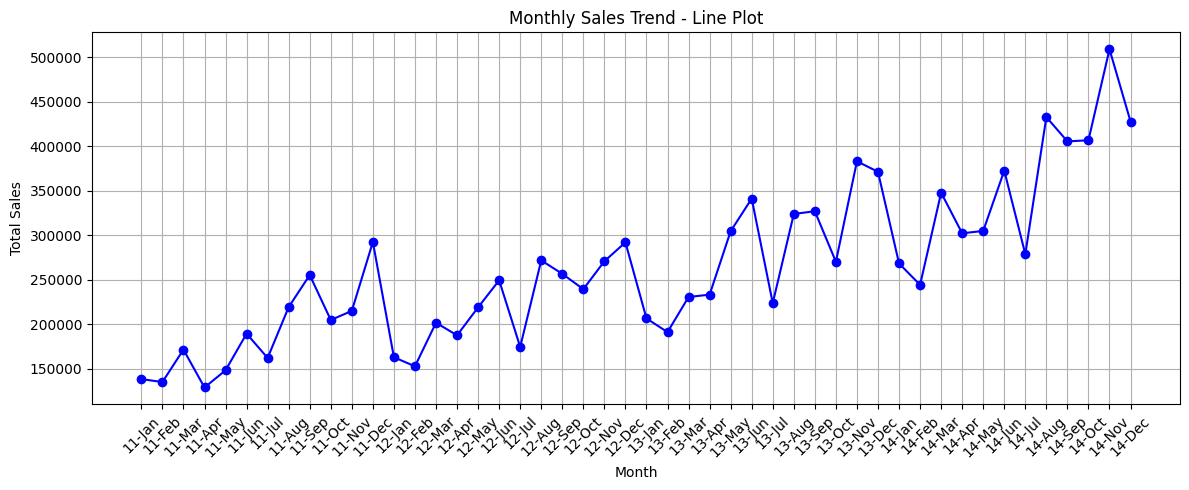

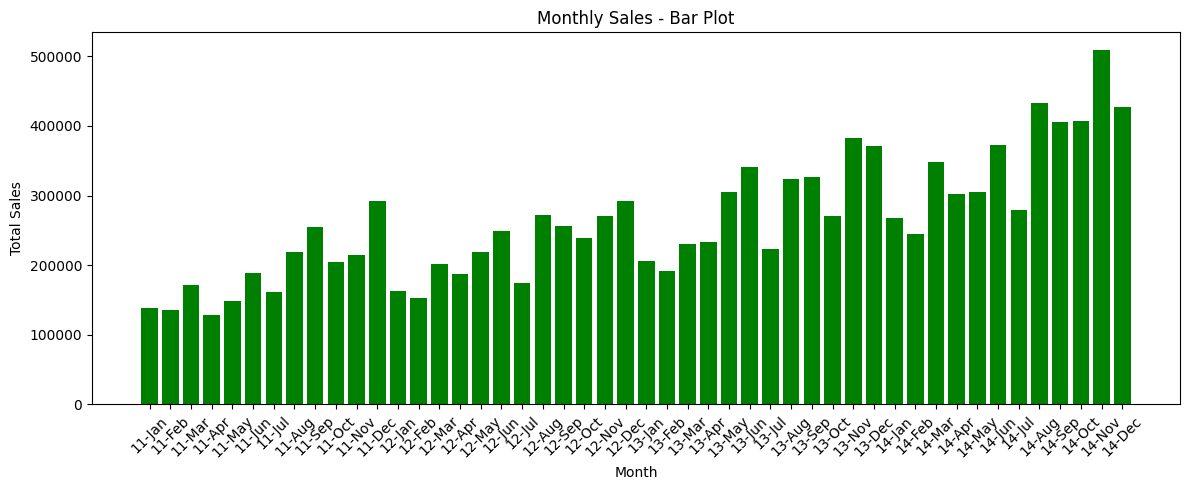

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset directly to ensure a clean state
df = pd.read_csv('/content/Exp10 - Exp10.csv')

# Ensure order_date is in datetime format, handling mixed date formats gracefully
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed')

# Clean the 'sales' column: remove commas and convert to numeric float
df['sales'] = df['sales'].astype(str).str.replace(',', '', regex=False)
df['sales'] = pd.to_numeric(df['sales'], errors='coerce').fillna(0)

# Group by month and sum the sales chronologically
monthly_data = df.groupby(df['order_date'].dt.to_period('M'))['sales'].sum().reset_index()
monthly_data = monthly_data.sort_values('order_date')

# Format the month labels as 'Yr-Mon' (e.g. '11-Jan')
months = monthly_data['order_date'].dt.strftime('%y-%b')
sales = monthly_data['sales'].tolist()

# Line Plot
plt.figure(figsize=(12, 5))
plt.plot(months, sales, marker="o", color="blue")
plt.title("Monthly Sales Trend - Line Plot")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Bar Plot
plt.figure(figsize=(12, 5))
plt.bar(months, sales, color="green")
plt.title("Monthly Sales - Bar Plot")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()